# المعمل التفاعلي: بناء أول شات بوت ذكي في LangGraph
## المحاضرة 75: SuperBot، مجمعات الحالة (Reducers)، والبث التدفقي (Streaming)

أهلاً بيك في المعمل التفاعلي!
في المحاضرات اللي فاتت، اتعلمنا إزاي نعمل عقد ونربطها بأسهم وقرارات شرطية بسيطة.
النهاردة بقى هندخل الذكاء الاصطناعي الحقيقي في الجراف ونبني **SuperBot** يقدر يرد على أسئلتنا، ويفهم المحادثات، ويتعلم إزاي يحافظ على تاريخ الشات وما يمسحوش!

### المحاور اللي هنجربها بإيدينا:
1. إيه هو الـ Reducer وليه بنحتاج `add_messages`؟
2. تشغيل الموديل السريع من خلال `ChatGroq`.
3. ربط النود وتشغيل الجراف بالـ `.invoke()`.
4. البث التدفقي `stream` بنوعيه: التحديثات السريعة (`updates`) ولقطات الحالة الكاملة (`values`).
5. قسم "جرب بنفسك!".

In [1]:
import os
from typing_extensions import TypedDict, Annotated
from dotenv import load_dotenv

from langchain_core.messages import HumanMessage, AIMessage
from langchain_groq import ChatGroq
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from IPython.display import Image, display

# تحميل مفاتيح البيئة
load_dotenv()
print("تم تحميل المكتبات ومفاتيح البيئة بنجاح!")

تم تحميل المكتبات ومفاتيح البيئة بنجاح!


In [2]:
# إعداد الموديل السريع من Groq LPU
llm = ChatGroq(
    model="openai/gpt-oss-20b",
    temperature=0.0,
    max_tokens=150
)

# تجربة سريعة للموديل
test_reply = llm.invoke("مرحباً! عرف نفسك بجملة واحدة.")
print("رد الموديل التجريبي:")
print(test_reply.content.strip())

رد الموديل التجريبي:
أنا ChatGPT، نموذج لغة ذكي من OpenAI، أساعدك في الإجابة على الأسئلة وتقديم المعلومات.


In [3]:
# تعريف حالة الشات بوت مع مجمع الرسائل add_messages
class ChatState(TypedDict):
    # لاحظ استخدام Annotated هنا لتحديد إن القائمة لا تستبدل بل تدمج تلقائياً
    messages: Annotated[list, add_messages]

print("تم تعريف مخطط الحالة ChatState بنجاح.")

تم تعريف مخطط الحالة ChatState بنجاح.


In [4]:
# تعريف دالة العقدة SuperBot
def super_bot(state: ChatState):
    all_messages = state["messages"]
    print(f"[عقدة SuperBot]: استلمت {len(all_messages)} رسالة سابقة في المحادثة.")
    
    # نبعث كل تاريخ المحادثة للـ LLM عشان يكون عنده السياق كامل
    response = llm.invoke(all_messages)
    
    # نرجع التحديث في قائمة، ومحرك LangGraph هيدمجه بالـ Reducer
    return {"messages": [response]}

print("تم تعريف عقدة super_bot بنجاح.")

تم تعريف عقدة super_bot بنجاح.


تم تجميع الجراف وجاهز للتشغيل!


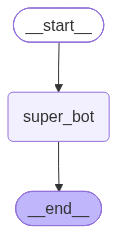

In [5]:
# بناء الجراف وتوصيل العقد
builder = StateGraph(ChatState)

builder.add_node("super_bot", super_bot)
builder.add_edge(START, "super_bot")
builder.add_edge("super_bot", END)

# التجميع
app = builder.compile()
print("تم تجميع الجراف وجاهز للتشغيل!")

# رسم المخطط البصري
try:
    display(Image(app.get_graph().draw_mermaid_png()))
except Exception:
    print(app.get_graph().draw_mermaid())

In [6]:
# تجربة الاستدعاء المباشر invoke
user_query = "أنا بحب البرمجة بلغة بايثون ومهتم بتطبيقات الـ AI. انصحني بنصيحة سريعة."
input_state = {"messages": [HumanMessage(content=user_query)]}

print("تشغيل الجراف عبر .invoke():")
print("-" * 50)
output_state = app.invoke(input_state)
print("-" * 50)

print(f"عدد الرسائل المسجلة في الحالة الآن: {len(output_state['messages'])}")
print("رد الـ SuperBot:")
print(output_state["messages"][-1].content.strip())

تشغيل الجراف عبر .invoke():
--------------------------------------------------
[عقدة SuperBot]: استلمت 1 رسالة سابقة في المحادثة.


--------------------------------------------------
عدد الرسائل المسجلة في الحالة الآن: 2
رد الـ SuperBot:
حافظ على التوازن بين التعلم النظري والتطبيق العملي:  
1. **ابدأ بمشاريع صغيرة** (مثل تصنيف الصور أو تحليل النص) باستخدام مكت


In [7]:
# تجربة البث التدفقي بنمط التحديثات: stream_mode='updates'
query = "قولي معلومة سريعة في سطر واحد عن الذكاء الاصطناعي."
stream_input = {"messages": [HumanMessage(content=query)]}

print("بدء البث بنمط التحديثات (updates):")
print("=" * 50)

for step, event in enumerate(app.stream(stream_input, stream_mode="updates"), start=1):
    print(f"الخطوة {step}: وصل تحديث من العقدة:")
    print(event)

print("=" * 50)

بدء البث بنمط التحديثات (updates):
[عقدة SuperBot]: استلمت 1 رسالة سابقة في المحادثة.


الخطوة 1: وصل تحديث من العقدة:
{'super_bot': {'messages': [AIMessage(content='', additional_kwargs={'reasoning_content': 'The user says: "قولي معلومة سريعة في سطر واحد عن الذكاء الاصطناعي." That is Arabic: "Tell me a quick fact in one line about artificial intelligence." So we need to give a quick fact in one line about AI. Should be concise. Probably something like: "الذكاء الاصطناعي هو فرع من علوم الكمبيوتر يهدف إلى إنشاء أنظمة تستطيع محاكاة الذكاء البشري." But one line. Let\'s produce a short fact. Maybe: "الذكاء الاصطناعي يمكنه تحليل ملايين البيانات في ثوانٍ، ما يتيح تحسينات في الطب، النقل، والاقتصاد." That is one line. Or "الذك'}, response_metadata={'token_usage': {'completion_tokens': 150, 'prompt_tokens': 90, 'total_tokens': 240, 'completion_time': 0.153646464, 'completion_tokens_details': {'reasoning_tokens': 148}, 'prompt_time': 0.004891819, 'prompt_tokens_details': None, 'queue_time': 0.208787603, 'total_time': 0.158538283}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerp

In [8]:
# تجربة البث التدفقي بنمط لقطة الحالة الكاملة: stream_mode='values'
query = "ما هي عاصمة مصر؟"
values_input = {"messages": [HumanMessage(content=query)]}

print("بدء البث بنمط لقطة الحالة الكاملة (values):")
print("=" * 50)

for step, snapshot in enumerate(app.stream(values_input, stream_mode="values"), start=1):
    messages_count = len(snapshot["messages"])
    print(f"اللقطة {step}: الحالة تحتوي على {messages_count} رسائل.")
    last_msg = snapshot["messages"][-1]
    role = "المستخدم" if isinstance(last_msg, HumanMessage) else "البوت"
    print(f"  آخر رسالة كانت من [{role}]: {last_msg.content.strip()[:60]}...")

print("=" * 50)

بدء البث بنمط لقطة الحالة الكاملة (values):
اللقطة 1: الحالة تحتوي على 1 رسائل.
  آخر رسالة كانت من [المستخدم]: ما هي عاصمة مصر؟...
[عقدة SuperBot]: استلمت 1 رسالة سابقة في المحادثة.


اللقطة 2: الحالة تحتوي على 2 رسائل.
  آخر رسالة كانت من [البوت]: عاصمة مصر هي القاهرة....


### جرب بنفسك! (Hands-on Experiments)

1. **تجربة تغيير الرسالة وملاحظة الرد:**
   جرب تبعت سؤال في مجالك وشوف إزاي البوت بيرد عليك.
2. **تجربة تمرير رسائل متعددة:**
   جرب تبعت في المدخلات قائمة فيها رسالتين: واحدة من المستخدم وواحدة قديمة من البوت، وشوف البوت هيتعامل معاهم إزاي.
3. **تجربة مقارنة updates بـ values:**
   لاحظ الفرق بين إنك تستلم التعديل فقط (`updates`) وبين إنك تستلم كائن الحالة كاملاً (`values`).

In [9]:
# مساحتك للتجربة الحرة:
my_messages = [
    HumanMessage(content="اسمي علي، وعندي مشروع تخرج عن أنظمة RAG."),
    AIMessage(content="أهلاً بك يا علي! أنظمة RAG مجال واعد ومطلوب جداً."),
    HumanMessage(content="كنت سألتك عن اسمي من شوية، فهل تفتكره؟")
]

test_res = app.invoke({"messages": my_messages})
print("رد البوت على المحادثة متعددة الجولات:")
print(test_res["messages"][-1].content.strip())

[عقدة SuperBot]: استلمت 3 رسالة سابقة في المحادثة.


رد البوت على المحادثة متعددة الجولات:
نعم، تذكرت اسمك. اسمي علي.
